### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy as sp

import json
import csv
import warnings
from os import listdir
import reframed

import libsbml
import matplotlib.pyplot as plt

import sys
sys.path.append("../functions/")
import compare_inter_exp_sim

In [2]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [3]:
glv_model_file = libsbml.readSBMLFromFile("../data/Venturelli2018/msb178157-sup-0006-codeev1/twelveSpeciesT4.xml")
glv_model = glv_model_file.getModel()

glv_model.getNumSpecies()

24

In [4]:
for param in glv_model.parameters:
    print(param.id)
    break

aBHBH


In [5]:
glv_parameters = {}

for param in glv_model.parameters:
    if param.id.startswith("a"):
        key = param.id
        glv_parameters[(key[1:3],key[3:])]=param.value

glv_param_ser = pd.Series(glv_parameters)

glv_param_ser.index.names = ["receiver","donor"]
glv_param_ser.name="gLV"

In [6]:
glv_param_ser.xs("EL",level=1).head(5)

receiver
BH    0.1764
BO    1.7566
BT    2.2719
BU    3.3782
BV    1.3026
Name: gLV, dtype: float64

In [7]:
glv_param_ser.xs("EL",level=0).head(5)

donor
BH    0.6924
BO   -0.1141
BT   -0.1688
BU   -0.1241
BV   -0.0493
Name: gLV, dtype: float64

**Load steadiercom results**

In [8]:
steadiercom_abundance= pd.read_csv("../output/Venturelli2018/results_steadiercom/results_abundance/NONE.tsv",sep="\t")

steadiercom_growth = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth/NONE.tsv",sep="\t")

steadiercom_growth_abundance = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance/NONE.tsv",sep="\t")

**Load smetana results**

In [9]:
smetana = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")
smetana = smetana[smetana.community=="NONE"]

**Load steadycom results**

In [11]:
steadycom_fixed_abundance = pd.read_csv("../output/Venturelli2018/steadycom/fixed_abundance/cross_feeding.tsv",sep="\t")
steadycom = pd.read_csv("../output/Venturelli2018/steadycom/no_abundance/cross_feeding.tsv",sep="\t")

steadycom = steadycom[steadycom.community=="NONE"]
steadycom.donor = steadycom.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom.receiver = steadycom.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)

steadycom_fixed_abundance.donor = steadycom_fixed_abundance.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom_fixed_abundance.receiver = steadycom_fixed_abundance.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)


**Process data: Remove environment for receiver (and/or donor) and change member names to initials**

In [12]:
steadiercom_dict = {
    "SteadierCom - Fixed growth":steadiercom_growth,
    "SteadierCom - Fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - Fixed abundance":steadiercom_abundance
}
steadiercom_dict_inter = {}

for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.donor!="environment") & (simulated.receiver!="environment")].copy()
    simulated.donor = simulated.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    simulated.receiver = simulated.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    steadiercom_dict_inter[name]=simulated


steadiercom_dict_rec = {}
for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.receiver!="environment")].copy()
    simulated.donor = simulated.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper() if x!="environment" else x)
    simulated.receiver = simulated.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    steadiercom_dict_rec[name]=simulated


steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed abundance":steadycom_fixed_abundance
}
steadycom_dict_inter = {}

for name,simulated in steadycom_dict.items():
    simulated = simulated.dropna().copy()
    simulated.donor = simulated.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    simulated.receiver = simulated.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    steadycom_dict_inter[name]=simulated


steadycom_dict_rec = {}
for name,simulated in steadycom_dict.items():
    simulated = simulated.fillna("environment")
    simulated = simulated[(simulated.receiver!="environment")].copy()   
    simulated.donor = simulated.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper() if x!="environment" else x)
    simulated.receiver = simulated.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    steadycom_dict_rec[name]=simulated


## Cooperation and competition - SteadierCom

#### SteadierCom - scatterplot - frequency count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:164: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = sp.stats.spearmanr(exp_sim_combined)
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


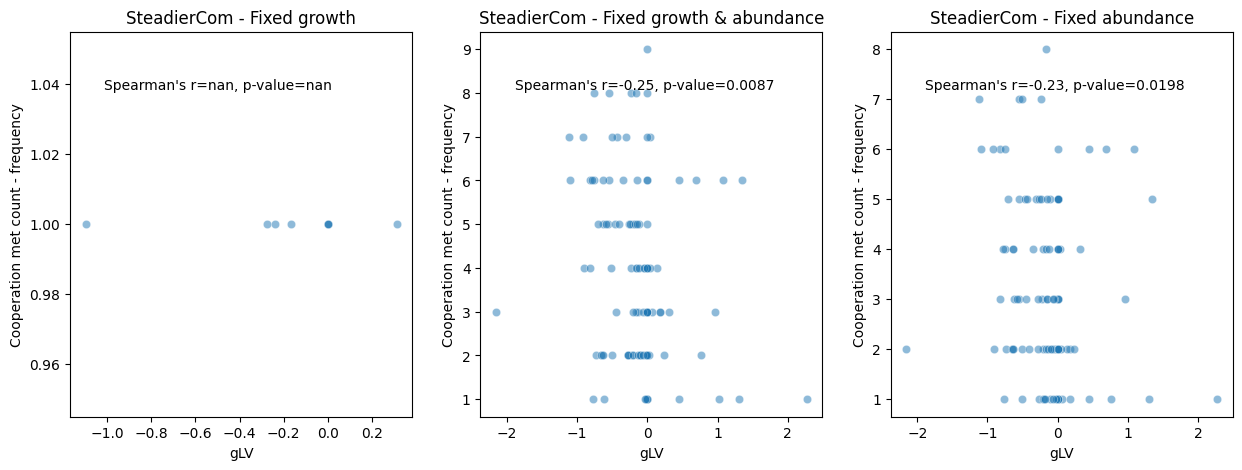

In [13]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_inter,
                                  glv_param_ser,
                                  coop_or_comp="coop",
                                  metric="frequency",
                                  sim_thresh =0.01,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    
    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


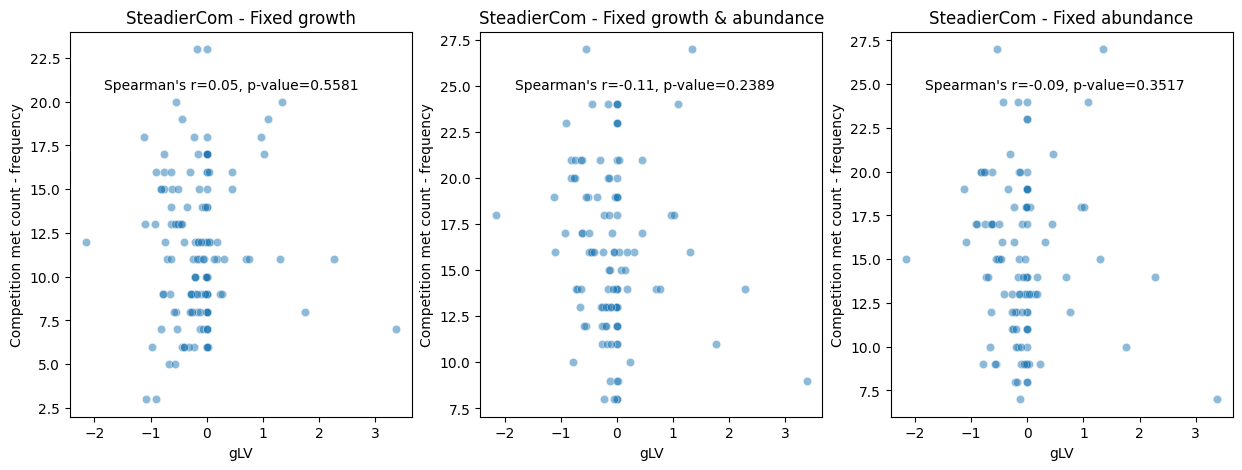

In [14]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_rec,
                                  glv_param_ser,
                                  coop_or_comp="comp",
                                  metric="frequency",
                                  sim_thresh =0.01,
                                  count_or_sum="count")


fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadierCom - scatterplot - rate count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


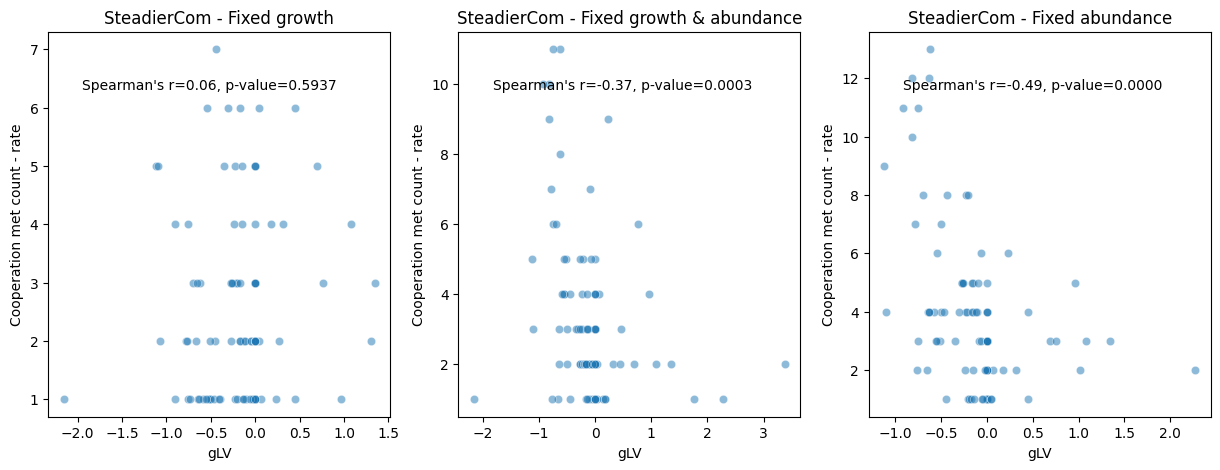

In [15]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_rec,
                                  glv_param_ser,
                                  coop_or_comp="coop",
                                  metric="rate",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


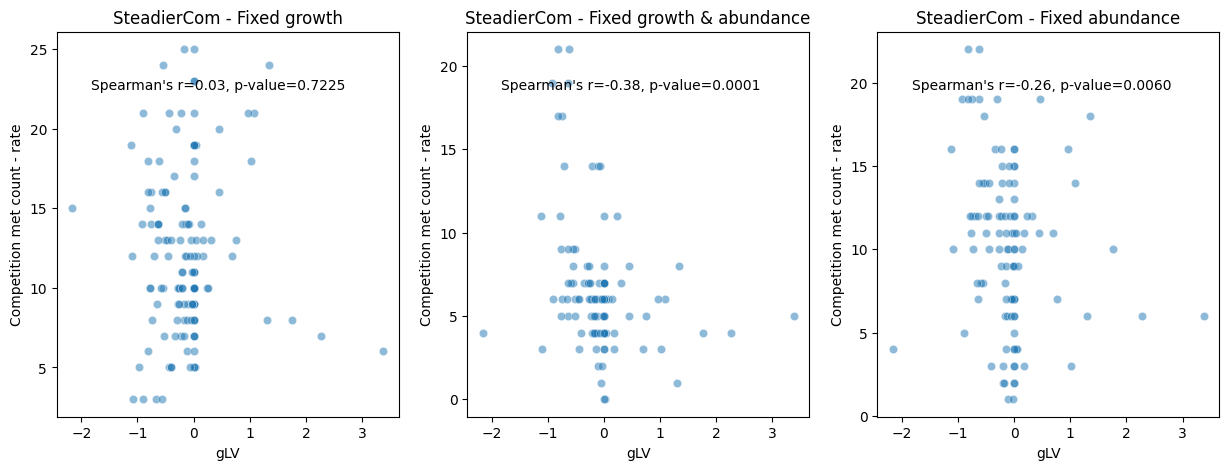

In [16]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadiercom_dict_rec,
                                  glv_param_ser,
                                  coop_or_comp="comp",
                                  metric="rate",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadyCom - scatterplot - rate count

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


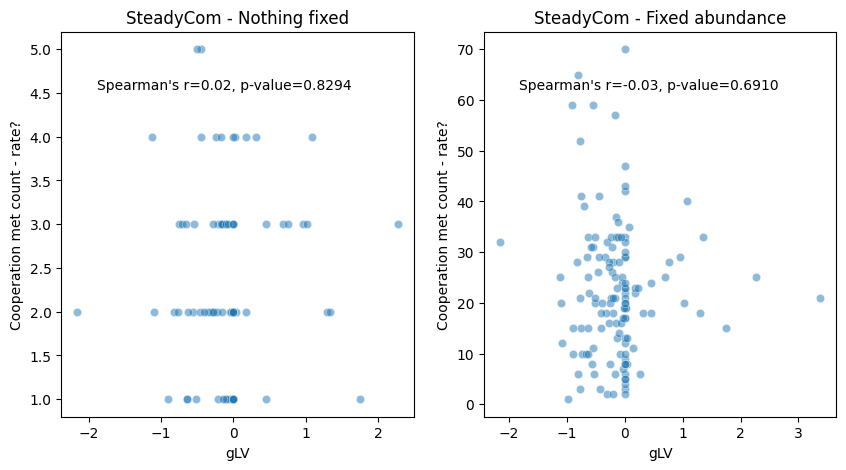

In [17]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadycom_dict_inter,
                                  glv_param_ser,
                                  coop_or_comp="coop",
                                  metric="rate?",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,2,figsize=(10,5))
i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())
[INFO] plot_coop_comp_venturelli filters exp_sim_combined (receiver!=donor + exp_sim_combined.dropna())


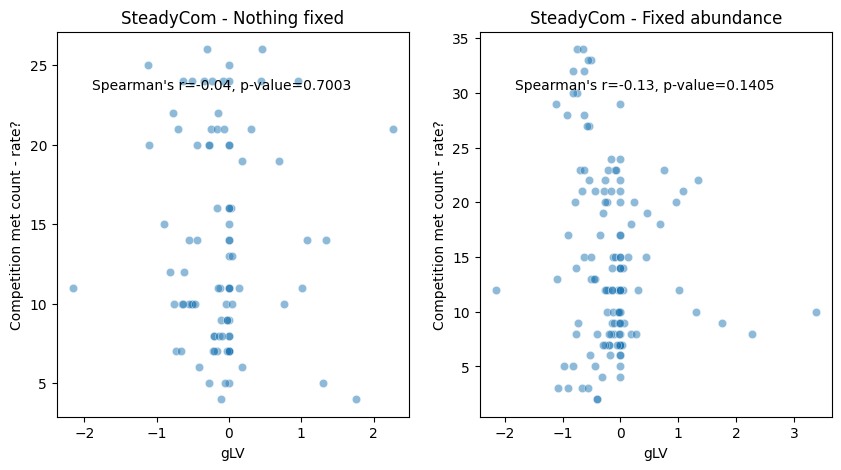

In [18]:
data_dict,label_dict = compare_inter_exp_sim.coop_or_comp_exp_communities(steadycom_dict_rec,
                                  glv_param_ser,
                                  coop_or_comp="comp",
                                  metric="rate?",
                                  sim_thresh =1e-3,
                                  count_or_sum="count")
fig, axs = plt.subplots(1,2,figsize=(10,5))
i = 0
for name,exp_sim_combined in data_dict.items():

    compare_inter_exp_sim.plot_coop_or_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

### Competition and cooperation - combined

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


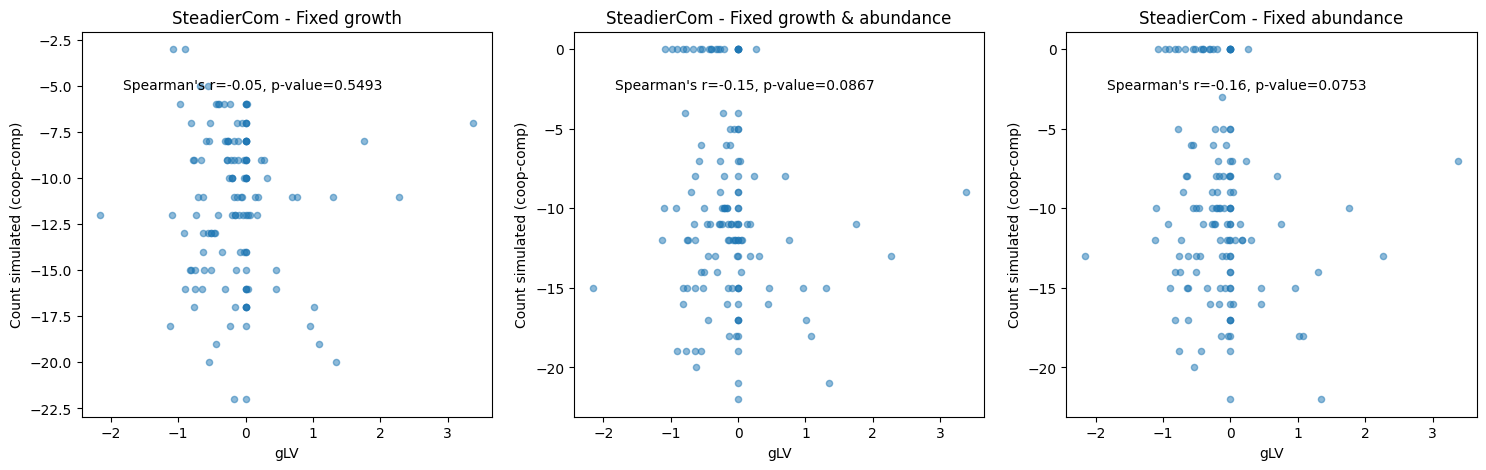

In [19]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=glv_param_ser,
                                              metric="frequency",
                                              count_or_sum="count",
                                              sim_thresh=0.01)

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


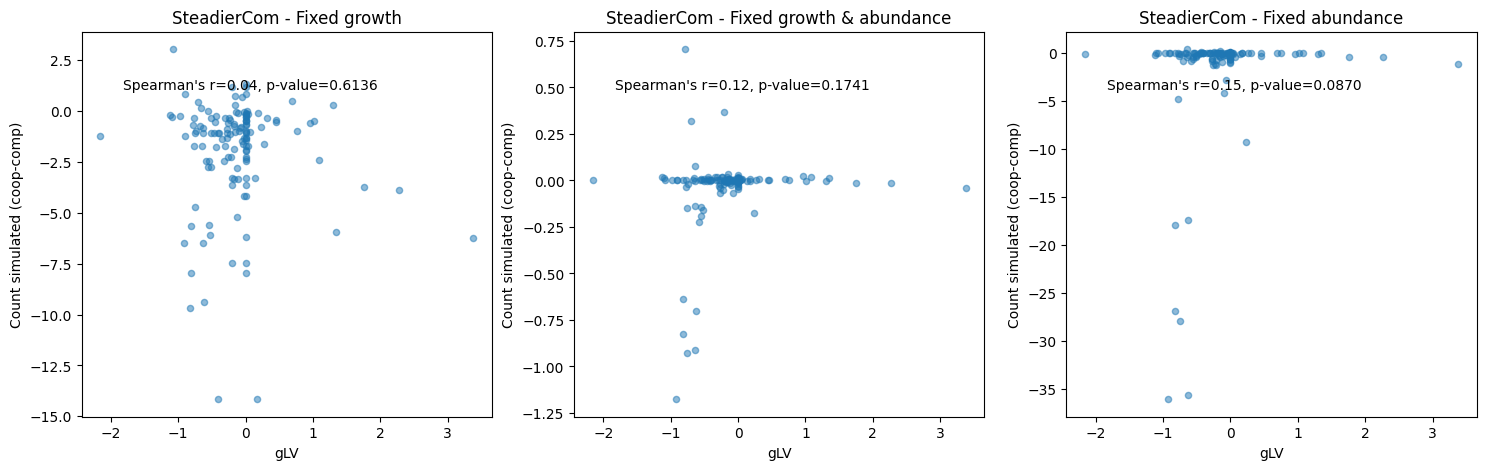

In [25]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=glv_param_ser,
                                              metric="rate",
                                              count_or_sum="sum",
                                              sim_thresh=False)




[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor. Before combining coop and comp, we use fillna(0)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:224: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


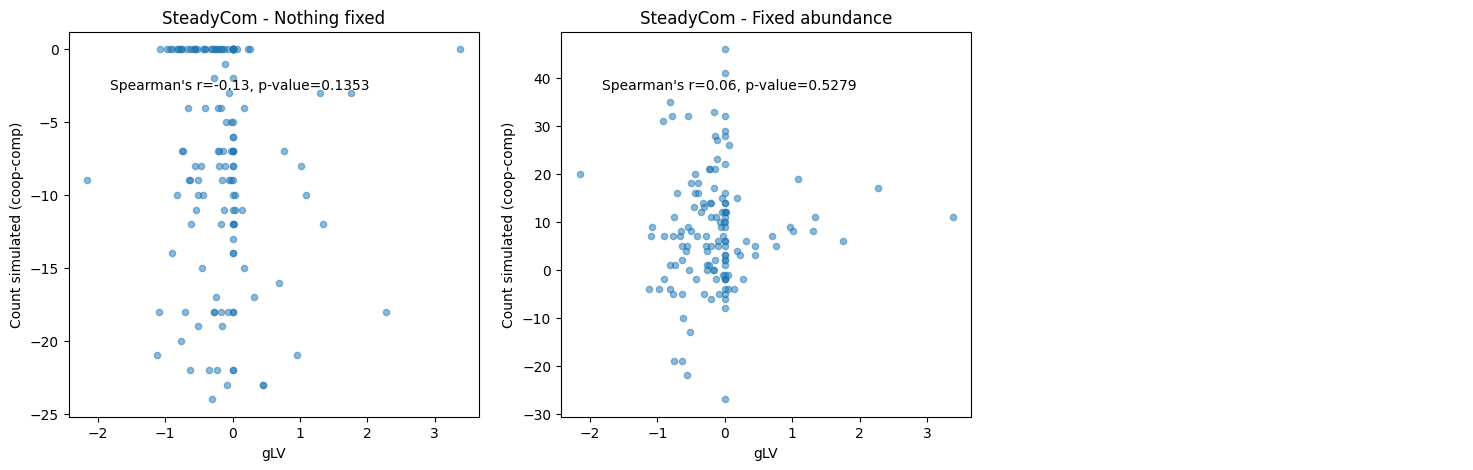

In [21]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadycom_dict_rec,
                                              simulated_dict_inter=steadycom_dict_inter,
                                              exp_ser=glv_param_ser,
                                              metric="rate?",
                                              count_or_sum="count",
                                              sim_thresh=1e-3)

axs[-1].set_axis_off()